# Assignment 5: Implement and Compare RNN, LSTM, GRU Models for Sequence Classification

**Goal:** Build a Simple RNN, an LSTM, and a GRU model for a sequence classification task
(sentiment analysis on the IMDB movie review dataset), train them under identical conditions,
and compare their performance using multiple evaluation metrics (Accuracy, Precision, Recall,
F1-score, Confusion Matrix, ROC-AUC) along with training-time and convergence behaviour.

**Dataset:** IMDB Movie Reviews (binary sentiment classification — positive/negative),
loaded directly from `tensorflow.keras.datasets`, so no external download/upload is needed.

**Pipeline:**
1. Load & preprocess data (tokenize, pad sequences)
2. Build RNN, LSTM, GRU models with a shared architecture (only the recurrent layer differs)
3. Train all three models under the same settings
4. Evaluate each on the test set
5. Compare metrics, training curves, confusion matrices, and ROC curves
6. Summarize findings


## 1. Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU available: []


## 2. Load & Preprocess the Dataset

We use the IMDB dataset (50,000 movie reviews labeled positive/negative).
Reviews are already encoded as sequences of word-index integers by Keras.
We:
- Restrict the vocabulary to the top `VOCAB_SIZE` most frequent words
- Pad/truncate every review to a fixed length `MAX_LEN`


In [5]:
VOCAB_SIZE = 10000   # keep only the top 10,000 most frequent words
MAX_LEN = 200         # pad/truncate every review to 200 tokens
EMBED_DIM = 128        # embedding vector size

(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print("Training samples:", len(x_train))
print("Test samples:", len(x_test))
print("Example review (as word indices):", x_train[0][:20])
print("Label:", y_train[0], "(1 = positive, 0 = negative)")

# Pad sequences to a fixed length
x_train = pad_sequences(x_train, maxlen=MAX_LEN, padding='post', truncating='post')
x_test  = pad_sequences(x_test,  maxlen=MAX_LEN, padding='post', truncating='post')

print("\nShape after padding:")
print("x_train:", x_train.shape, " x_test:", x_test.shape)

# Class balance
print("\nClass balance (train):", np.bincount(y_train))
print("Class balance (test):", np.bincount(y_test))


Training samples: 25000
Test samples: 25000
Example review (as word indices): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
Label: 1 (1 = positive, 0 = negative)

Shape after padding:
x_train: (25000, 200)  x_test: (25000, 200)

Class balance (train): [12500 12500]
Class balance (test): [12500 12500]


## 3. Model Architectures

To make the comparison fair, all three models share the **same** architecture
(Embedding → Recurrent layer → Dropout → Dense output) and only the recurrent
layer type differs (`SimpleRNN`, `LSTM`, `GRU`).


In [6]:
def build_model(rnn_type: str, units: int = 64) -> Sequential:
    """Build a sequence classification model using the specified recurrent layer."""
    model = Sequential(name=f"{rnn_type}_model")
    model.add(Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, input_length=MAX_LEN))

    if rnn_type == "RNN":
        model.add(SimpleRNN(units, dropout=0.2, recurrent_dropout=0.2))
    elif rnn_type == "LSTM":
        model.add(LSTM(units, dropout=0.2, recurrent_dropout=0.2))
    elif rnn_type == "GRU":
        model.add(GRU(units, dropout=0.2, recurrent_dropout=0.2))
    else:
        raise ValueError("rnn_type must be one of 'RNN', 'LSTM', 'GRU'")

    model.add(Dropout(0.3))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Quick sanity check of architecture
build_model("LSTM").summary()


c:\Users\Raj\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "LSTM_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 4. Train RNN, LSTM, and GRU Models

Each model is trained with identical hyperparameters (epochs, batch size, optimizer,
validation split, early stopping) so that any performance difference reflects the
architecture rather than the training setup.


In [7]:
EPOCHS = 10
BATCH_SIZE = 128
VALIDATION_SPLIT = 0.2

model_types = ["RNN", "LSTM", "GRU"]
histories = {}
models = {}
train_times = {}

early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

for m_type in model_types:
    print(f"\n{'='*60}\nTraining {m_type} model\n{'='*60}")
    model = build_model(m_type)

    start = time.time()
    history = model.fit(
        x_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=VALIDATION_SPLIT,
        callbacks=[early_stop],
        verbose=1
    )
    elapsed = time.time() - start

    models[m_type] = model
    histories[m_type] = history
    train_times[m_type] = elapsed
    print(f"{m_type} training time: {elapsed:.2f} seconds")



Training RNN model
Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 108ms/step - accuracy: 0.5042 - loss: 0.7187 - val_accuracy: 0.5098 - val_loss: 0.6938
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 102ms/step - accuracy: 0.5089 - loss: 0.7064 - val_accuracy: 0.5016 - val_loss: 0.6932
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 103ms/step - accuracy: 0.5113 - loss: 0.6996 - val_accuracy: 0.5022 - val_loss: 0.6933
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 101ms/step - accuracy: 0.5151 - loss: 0.6954 - val_accuracy: 0.5054 - val_loss: 0.6933
RNN training time: 67.97 seconds

Training LSTM model
Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 82s 502ms/step - accuracy: 0.5148 - loss: 0.6925 - val_accuracy: 0.5544 - val_loss: 0.6835
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 78s 497ms/step - accuracy: 0.5759 - loss: 0.6800 - val_accuracy: 0.5538 - val_loss: 0.6785
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 77s 491ms/step - accuracy: 0.6445 - loss: 0.6235 - val_accuracy: 0.7482 - val_loss: 0.5865
Epoch 4/1

## 5. Evaluate on the Test Set

For each model we compute:
- **Accuracy, Precision, Recall, F1-score**
- **Confusion Matrix**
- **ROC curve & AUC**
- **Test loss**


In [8]:
results = {}
predictions = {}
probabilities = {}

for m_type, model in models.items():
    y_prob = model.predict(x_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

    results[m_type] = {
        "Test Loss": test_loss,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "Training Time (s)": train_times[m_type],
        "Params": model.count_params(),
    }
    predictions[m_type] = y_pred
    probabilities[m_type] = y_prob

results_df = pd.DataFrame(results).T
results_df = results_df[["Accuracy", "Precision", "Recall", "F1-Score", "Test Loss", "Training Time (s)", "Params"]]
results_df.round(4)


,Accuracy,Precision,Recall,F1-Score,Test Loss,Training Time (s),Params
RNN,0.4962,0.4840,0.1152,0.1861,0.6933,67.9665,1292417.0
LSTM,0.7683,0.8090,0.7026,0.7520,0.5316,671.0380,1329473.0
GRU,0.8434,0.8744,0.8020,0.8366,0.3816,499.9654,1317313.0


In [9]:
for m_type in model_types:
    print(f"\n{'='*20} {m_type} — Classification Report {'='*20}")
    print(classification_report(y_test, predictions[m_type], target_names=["Negative", "Positive"]))



==================== RNN — Classification Report ====================
              precision    recall  f1-score   support

    Negative       0.50      0.88      0.64     12500
    Positive       0.48      0.12      0.19     12500

    accuracy                           0.50     25000
   macro avg       0.49      0.50      0.41     25000
weighted avg       0.49      0.50      0.41     25000


==================== LSTM — Classification Report ====================
              precision    recall  f1-score   support

    Negative       0.74      0.83      0.78     12500
    Positive       0.81      0.70      0.75     12500

    accuracy                           0.77     25000
   macro avg       0.77      0.77      0.77     25000
weighted avg       0.77      0.77      0.77     25000


==================== GRU — Classification Report ====================
              precision    recall  f1-score   support

    Negative       0.82      0.88      0.85     12500
    Positive       0.87

## 6. Confusion Matrices

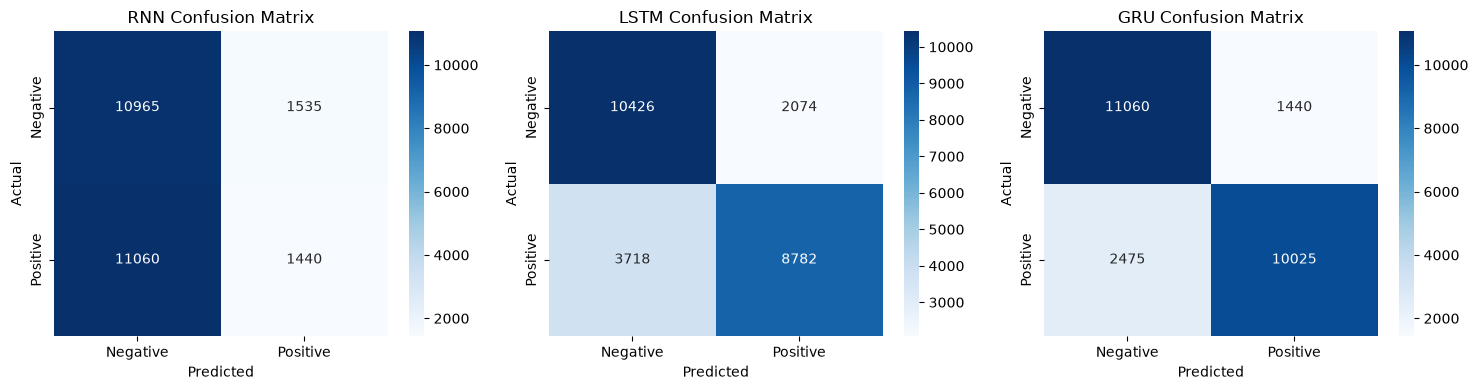

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, m_type in zip(axes, model_types):
    cm = confusion_matrix(y_test, predictions[m_type])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
    ax.set_title(f"{m_type} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


## 7. Training Curves — Accuracy & Loss

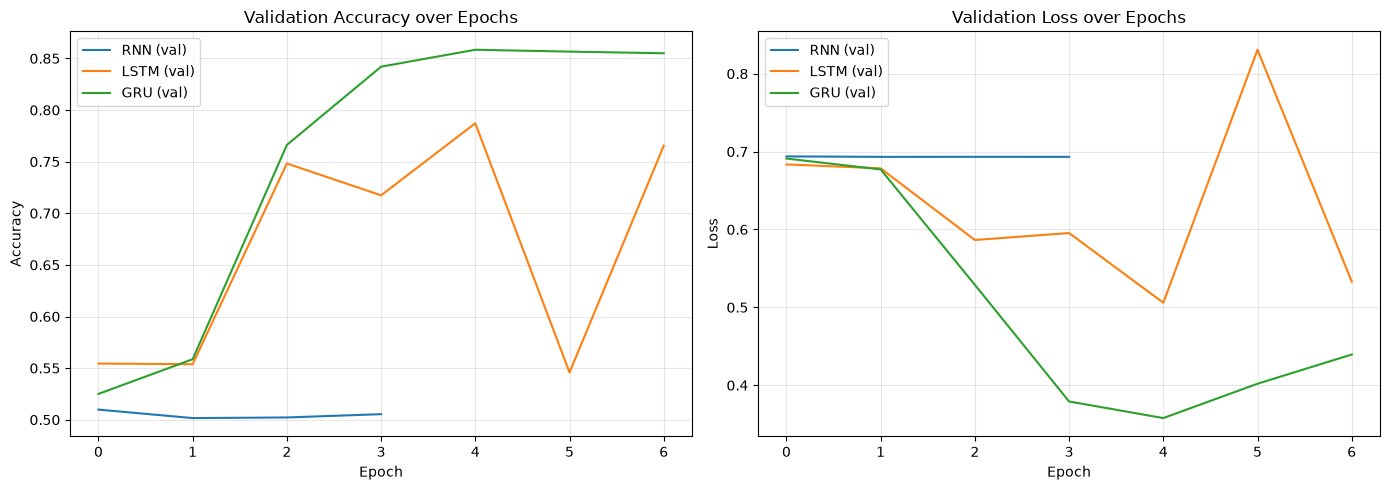

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for m_type in model_types:
    h = histories[m_type].history
    axes[0].plot(h['val_accuracy'], label=f"{m_type} (val)")
    axes[1].plot(h['val_loss'], label=f"{m_type} (val)")

axes[0].set_title("Validation Accuracy over Epochs")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].set_title("Validation Loss over Epochs")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 8. ROC Curves & AUC

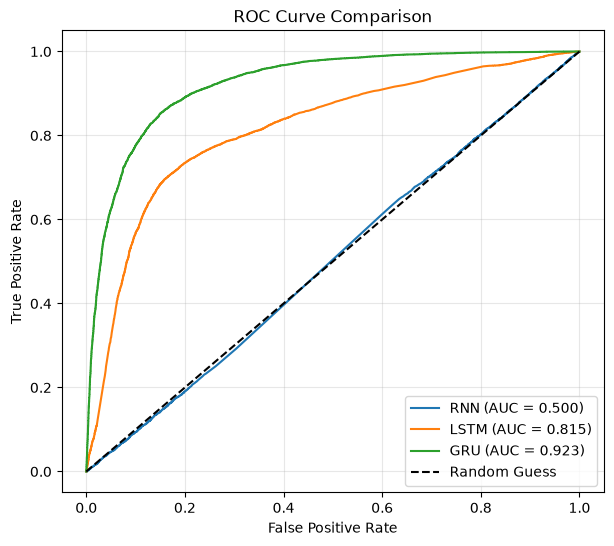

In [12]:
plt.figure(figsize=(7, 6))

for m_type in model_types:
    fpr, tpr, _ = roc_curve(y_test, probabilities[m_type])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{m_type} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 9. Side-by-Side Metric Comparison

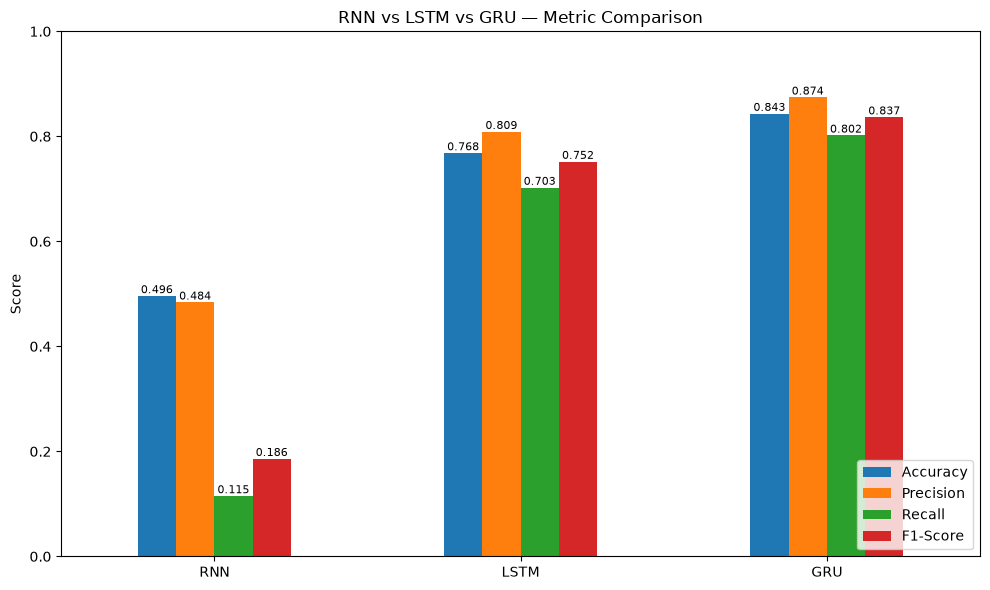


Final Comparison Table:


,Accuracy,Precision,Recall,F1-Score,Test Loss,Training Time (s),Params
RNN,0.4962,0.4840,0.1152,0.1861,0.6933,67.9665,1292417.0
LSTM,0.7683,0.8090,0.7026,0.7520,0.5316,671.0380,1329473.0
GRU,0.8434,0.8744,0.8020,0.8366,0.3816,499.9654,1317313.0


In [13]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score"]
plot_df = results_df[metrics_to_plot].astype(float)

ax = plot_df.plot(kind='bar', figsize=(10, 6), rot=0)
ax.set_title("RNN vs LSTM vs GRU — Metric Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.show()

print("\nFinal Comparison Table:")
results_df.round(4)


## 10. Observations & Conclusion

Fill in after running the notebook on your machine (numbers vary by run/hardware/seed):

- **Accuracy / F1:** Which model achieved the best classification performance, and by how much?
- **Training time:** SimpleRNN is typically fastest per epoch but LSTM/GRU usually converge
  in fewer epochs and reach better accuracy due to their gating mechanisms handling
  long-range dependencies and mitigating vanishing gradients.
- **Vanishing gradients:** SimpleRNN often underperforms on longer sequences (`MAX_LEN=200`)
  because of vanishing/exploding gradients; LSTM and GRU are designed to address this via
  gating (forget/input/output gates for LSTM; reset/update gates for GRU).
- **LSTM vs GRU:** GRU has fewer parameters (no separate cell state) and often trains faster
  with comparable accuracy to LSTM, making it a good lightweight alternative.
- **Overfitting:** Compare train vs. validation curves — note which model overfits fastest.

**General takeaway:** For moderate-length sequence classification tasks like sentiment
analysis, LSTM and GRU typically outperform SimpleRNN, with GRU offering a good
accuracy/efficiency trade-off and LSTM sometimes edging out slightly higher accuracy at the
cost of more parameters and longer training time.
